1. Obtenção e tratamento dos dados

In [ ]:
import os
import sys
import json
import re
from pathlib import Path
import pandas as pd

# Suporte a UTF-8 no Windows Console / Notebook
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")

# Localiza a raiz do projeto aJudAI e adiciona ao sys.path
RAIZ = Path.cwd()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.database.mongo_connection import MongoConnection

# Funções originais de limpeza e geração sintética
stop_words = {'o', 'a', 'os', 'as', 'de', 'do', 'da', 'em', 'no', 'na', 'para', 'com', 'por', 'que', 'se', 'é', 'não', 'dos', 'das', 'aos', 'ou', 'como', 'sobre'}

def limpar_texto(texto):
    if not isinstance(texto, str): return ""
    texto = texto.lower()
    texto = re.sub(r'[^\w\s]', ' ', texto)
    return re.sub(r'\s+', ' ', texto).strip()

def extrair_palavras_chave(texto_limpo):
    palavras = texto_limpo.split()
    keywords = [p for p in palavras if p not in stop_words and len(p) > 3]
    return " ".join(keywords[:6])

def gerar_perguntas_sinteticas(texto_limpo):
    keywords = extrair_palavras_chave(texto_limpo)
    if not keywords: return [texto_limpo]
    return [
        texto_limpo,
        f"o que a legislação diz sobre {keywords}",
        f"qual é a regra jurídica aplicável a {keywords}",
        f"como o código civil trata o tema de {keywords}"
    ]

# Conectar ao MongoDB para carregar os artigos vigentes do Código Civil
db = MongoConnection().get_db()
artigos_cursor = db["artigos"].find({"vigente": True})

# Dicionário de lookup para consulta rápida de citação e texto na inferência (Fix Célula 7)
artigos_dict = {}
dados_sinteticos = []

for doc in artigos_cursor:
    id_artigo = doc["_id"]
    citacao = doc.get("citacao", f"Código Civil, {id_artigo}")
    texto_artigo = doc.get("texto_vigente") or doc.get("texto") or ""
    
    # Armazena citação e texto autênticos no lookup
    artigos_dict[id_artigo] = {
        "citacao": citacao,
        "texto": texto_artigo
    }
    
    texto_limpo = limpar_texto(doc.get("texto", "") or texto_artigo)
    if texto_limpo:
        for var in gerar_perguntas_sinteticas(texto_limpo):
            dados_sinteticos.append({"texto": var, "label": id_artigo, "origem": "sintetico"})

df_sintetico = pd.DataFrame(dados_sinteticos)

# Função para carregar perguntas reais dos arquivos JSONL do projeto
PASTA_DATASET = RAIZ / "data" / "dataset"

def carregar_jsonl(nome_arquivo):
    caminho = PASTA_DATASET / nome_arquivo
    dados = []
    if caminho.exists():
        with open(caminho, "r", encoding="utf-8") as f:
            for linha in f:
                if linha.strip():
                    obj = json.loads(linha)
                    dados.append({
                        "texto": limpar_texto(obj["pergunta"]),
                        "label": obj["artigo_id"],
                        "origem": "real"
                    })
    else:
        print(f"Aviso: Arquivo {caminho} não encontrado!")
    return pd.DataFrame(dados)

# Carregar os dados reais
df_pares_bert = carregar_jsonl("pares_bert_inicial.jsonl")
df_avaliacao = carregar_jsonl("avaliacao_inicial.jsonl")

# Construir os conjuntos definitivos de Treino e Validação
df_treino = pd.concat([df_sintetico, df_pares_bert], ignore_index=True)
df_validacao = df_avaliacao.copy()

print(f"Total de exemplos de TREINO: {df_treino.shape[0]} (Sintéticos: {df_sintetico.shape[0]} + Pares BERT: {df_pares_bert.shape[0]})")
print(f"Total de exemplos de VALIDAÇÃO: {df_validacao.shape[0]} (Avaliação Inicial puramente humana)")
print(f"Total de artigos no lookup (MongoDB): {len(artigos_dict)}")


Total de exemplos de TREINO: 8324 (Sintéticos + Pares BERT)
Total de exemplos de VALIDAÇÃO: 12 (Avaliação Inicial puramente humana)


2. Classificação e vetorização do vocabulário

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
import torch
import numpy as np

# Junta dados de treino e validação
df_completo = pd.concat([df_treino, df_validacao], ignore_index=True)

# Mapeia todas as classes possíveis (unindo datasets e artigos do MongoDB)
todas_as_classes = sorted(list(set(df_completo['label']).union(set(artigos_dict.keys()))))
label_encoder = LabelEncoder()
label_encoder.fit(todas_as_classes)
num_classes = len(label_encoder.classes_)

# Transforma os rótulos de texto em números para a Rede Neural
df_treino['label_encoded'] = label_encoder.transform(df_treino['label'])
df_validacao['label_encoded'] = label_encoder.transform(df_validacao['label'])

X_treino = df_treino['texto']
Y_treino = df_treino['label_encoded']

X_valid = df_validacao['texto']
Y_valid = df_validacao['label_encoded']

# Vetorização TF-IDF (Aprende o vocabulário apenas no TREINO)
vetorizador = TfidfVectorizer(max_features=5000)
X_treino_tfidf = vetorizador.fit_transform(X_treino)
X_valid_tfidf = vetorizador.transform(X_valid)

# Conversão para Tensores do PyTorch
X_treino_tensor = torch.tensor(X_treino_tfidf.toarray(), dtype=torch.float32)
Y_treino_tensor = torch.tensor(Y_treino.values, dtype=torch.long)

X_valid_tensor = torch.tensor(X_valid_tfidf.toarray(), dtype=torch.float32)
Y_valid_tensor = torch.tensor(Y_valid.values, dtype=torch.long)

tamanho_vocabulario = X_treino_tensor.shape[1]
print(f"Tamanho do vocabulário (TF-IDF): {tamanho_vocabulario}")
print(f"Número de classes (Artigos mapeados): {num_classes}")


Tamanho do vocabulário (TF-IDF): 5000
Número de classes (Artigos mapeados): 2063


3. Criação do modelo e treino

A treinar no dispositivo: cpu
Epoch: 1/20 | Train Loss: 7.5145 | Val Loss: 6.7358 | Val Acc: 33.33%
Epoch: 2/20 | Train Loss: 4.4803 | Val Loss: 4.6249 | Val Acc: 25.00%
Epoch: 3/20 | Train Loss: 0.6534 | Val Loss: 3.1839 | Val Acc: 66.67%
Epoch: 4/20 | Train Loss: 0.2064 | Val Loss: 2.4236 | Val Acc: 58.33%
Epoch: 5/20 | Train Loss: 0.1472 | Val Loss: 2.0859 | Val Acc: 83.33%
Epoch: 6/20 | Train Loss: 0.1284 | Val Loss: 1.8702 | Val Acc: 75.00%
Epoch: 7/20 | Train Loss: 0.1188 | Val Loss: 1.8344 | Val Acc: 66.67%
Epoch: 8/20 | Train Loss: 0.1129 | Val Loss: 1.7309 | Val Acc: 75.00%
Epoch: 9/20 | Train Loss: 0.1085 | Val Loss: 1.6375 | Val Acc: 75.00%
Epoch: 10/20 | Train Loss: 0.1095 | Val Loss: 1.5397 | Val Acc: 75.00%
Epoch: 11/20 | Train Loss: 0.1046 | Val Loss: 1.5029 | Val Acc: 66.67%
Epoch: 12/20 | Train Loss: 0.1062 | Val Loss: 1.5021 | Val Acc: 66.67%
Epoch: 13/20 | Train Loss: 0.1022 | Val Loss: 1.4079 | Val Acc: 75.00%
Epoch: 14/20 | Train Loss: 0.1004 | Val Loss: 1.4024 | V

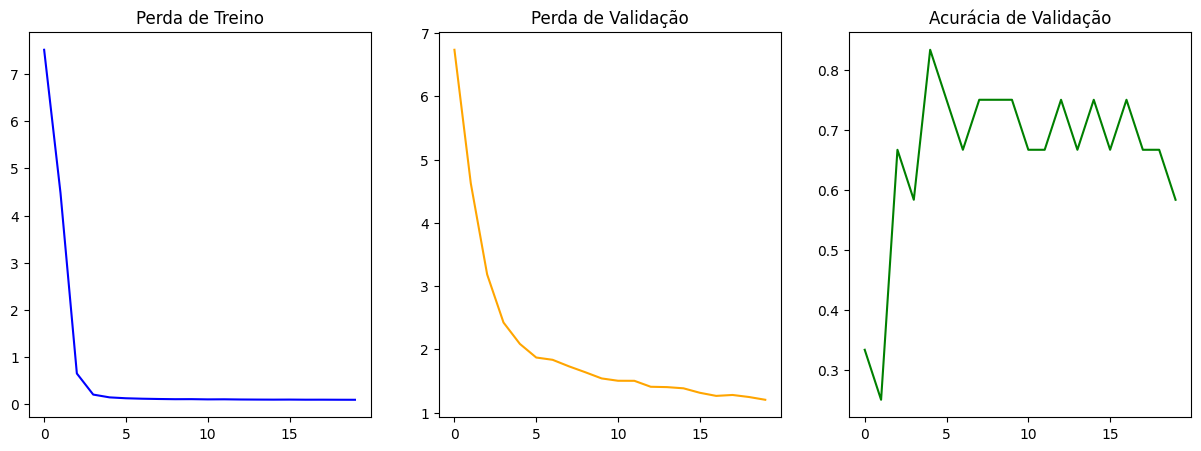

In [ ]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import pickle

# Criação dos Datasets e DataLoaders
dataset_treino = TensorDataset(X_treino_tensor, Y_treino_tensor)
dataloader_train = DataLoader(dataset_treino, batch_size=32, shuffle=True)

dataset_valid = TensorDataset(X_valid_tensor, Y_valid_tensor)
dataloader_val = DataLoader(dataset_valid, batch_size=32, shuffle=False)

# Arquitetura da Rede Neural Densa (MLP)
class ModeloClassicoTFIDF(nn.Module):
    def __init__(self, tamanho_vocabulario, num_classes):
        super(ModeloClassicoTFIDF, self).__init__()
        self.fc1 = nn.Linear(tamanho_vocabulario, 512)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.dropout(out)
        out = self.fc2(out)
        return out

# Instanciação do modelo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modelo_tfidf = ModeloClassicoTFIDF(tamanho_vocabulario, num_classes).to(device)

hyperparameters = {
    'learning_rate': 0.001,
    'n_epochs': 20,
    'model_name': 'TFIDF_MLP'
}

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(modelo_tfidf.parameters(), lr=hyperparameters['learning_rate'])

epoch_arr, train_loss_arr, val_loss_arr, acc_arr = [], [], [], []
min_val_loss = float('inf')
best_epoch = 0

# Diretório padrão para persistência dos modelos
PASTA_MODELOS = RAIZ / "data" / "models" / "tfidf_mlp"
PASTA_MODELOS.mkdir(parents=True, exist_ok=True)

print(f"A treinar no dispositivo: {device}")

for epoch in range(hyperparameters['n_epochs']):
    epoch_arr.append(epoch)
    total_loss = 0

    modelo_tfidf.train()
    for x_train, y_train in dataloader_train:
        x_train, y_train = x_train.to(device), y_train.to(device)
        outputs = modelo_tfidf(x_train)
        batch_loss = criterion(outputs, y_train)

        optimizer.zero_grad()
        batch_loss.backward()
        optimizer.step()
        total_loss += batch_loss.item()

    train_loss = total_loss / len(dataloader_train)
    train_loss_arr.append(train_loss)

    total_val_loss = 0
    total_acc = 0
    modelo_tfidf.eval()
    with torch.no_grad():
        for x_val, y_val in dataloader_val:
            x_val, y_val = x_val.to(device), y_val.to(device)
            outputs = modelo_tfidf(x_val)
            batch_loss = criterion(outputs, y_val)
            preds = outputs.argmax(dim=1)
            total_acc += (preds == y_val).sum().item()
            total_val_loss += batch_loss.item()

    val_loss = total_val_loss / len(dataloader_val)
    val_loss_arr.append(val_loss)
    val_acc = total_acc / len(dataset_valid)
    acc_arr.append(val_acc)

    print(f'Epoch: {epoch+1}/{hyperparameters["n_epochs"]} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%')

    if val_loss < min_val_loss:
        min_val_loss = val_loss
        best_epoch = epoch
        torch.save(modelo_tfidf.state_dict(), 'best_model_tfidf.pt')
        torch.save(modelo_tfidf.state_dict(), PASTA_MODELOS / 'modelo_classico.pt')

print(f'Melhor modelo guardado na epoch: {best_epoch+1}')

# Salvar artefatos adicionais para produção (Milestone 3)
with open(PASTA_MODELOS / "vectorizer.pkl", "wb") as f:
    pickle.dump(vetorizador, f)
with open(PASTA_MODELOS / "label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)
with open(PASTA_MODELOS / "metadata.json", "w", encoding="utf-8") as f:
    json.dump({
        "model_name": "TFIDF_MLP",
        "tamanho_vocabulario": tamanho_vocabulario,
        "num_classes": num_classes,
        "best_epoch": best_epoch + 1,
        "val_loss": min_val_loss,
        "val_acc": acc_arr[best_epoch]
    }, f, indent=2)

# Gráficos da evolução
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
ax1.plot(epoch_arr, train_loss_arr, label='Train Loss', color='blue')
ax1.set_title('Perda de Treino')
ax2.plot(epoch_arr, val_loss_arr, label='Val Loss', color='orange')
ax2.set_title('Perda de Validação')
ax3.plot(epoch_arr, acc_arr, label='Val Acc', color='green')
ax3.set_title('Acurácia de Validação')
plt.show()


4. Teste prático

In [ ]:
import torch.nn.functional as F
import json
import os
from pathlib import Path

# 1. Função base (Core) isolada para previsão Top-K
def prever_artigos(pergunta, top_n=3):
    modelo_tfidf.eval()

    pergunta_limpa = limpar_texto(pergunta)
    vetor_pergunta = vetorizador.transform([pergunta_limpa])
    tensor_pergunta = torch.tensor(vetor_pergunta.toarray(), dtype=torch.float32).to(device)

    with torch.no_grad():
        outputs = modelo_tfidf(tensor_pergunta)
        probabilidades = F.softmax(outputs, dim=1)
        scores, indices = torch.topk(probabilidades, top_n)

    resultados = []
    for i in range(top_n):
        idx_classe = indices[0][i].item()
        score_confianca = scores[0][i].item()
        id_artigo = label_encoder.inverse_transform([idx_classe])[0]
        resultados.append((id_artigo, score_confianca))

    return resultados

# 2. Teste manual com recuperação autêntica via artigos_dict (Correção do lookup de artigos)
def testar_modelo_como_usuario(pergunta, top_n=3):
    print(f"Pergunta do Usuário: '{pergunta}'\n")
    print("-" * 50)

    resultados = prever_artigos(pergunta, top_n)

    for i, (id_artigo, score_confianca) in enumerate(resultados):
        info_artigo = artigos_dict.get(id_artigo, {})
        citacao = info_artigo.get("citacao", f"Código Civil, {id_artigo}")
        texto_artigo = info_artigo.get("texto", "Texto não disponível.")

        print(f"Sugestão {i+1}: {citacao} ({id_artigo})")
        print(f"   Confiança: {score_confianca * 100:.2f}%")
        print(f"   Trecho da Lei: {texto_artigo.strip()}")
        print("-" * 50)

# 3. Avaliação automatizada consumindo PASTA_DATASET
def avaliar_arquivos(arquivos_teste, caminho_base=PASTA_DATASET, top_n=3):
    total_perguntas, acertos_top1, acertos_topn, ignoradas = 0, 0, 0, 0
    classes_conhecidas = set(label_encoder.classes_)

    for nome_arquivo in arquivos_teste:
        caminho_completo = Path(caminho_base) / nome_arquivo
        if not caminho_completo.exists():
            print(f"Arquivo ignorado (não encontrado): {caminho_completo}")
            continue

        with open(caminho_completo, 'r', encoding='utf-8') as f:
            for linha in f:
                linha = linha.strip()
                if not linha: continue

                try:
                    dados = json.loads(linha)
                    pergunta = dados.get("pergunta", "")
                    artigo_correto = dados.get("artigo_id", "")

                    if artigo_correto not in classes_conhecidas:
                        ignoradas += 1
                        continue

                    previsoes = prever_artigos(pergunta, top_n)
                    ids_previstos = [prev[0] for prev in previsoes]

                    if ids_previstos[0] == artigo_correto:
                        acertos_top1 += 1
                    if artigo_correto in ids_previstos:
                        acertos_topn += 1

                    total_perguntas += 1
                except json.JSONDecodeError:
                    pass

    print("=" * 50)
    print("AVALIAÇÃO EM LOTE")
    print(f"Arquivos: {', '.join(arquivos_teste)}")
    print("=" * 50)
    print(f"Total avaliadas: {total_perguntas} | Ignoradas: {ignoradas}")
    if total_perguntas > 0:
        print(f"Acurácia Top-1: {(acertos_top1 / total_perguntas) * 100:.2f}%")
        print(f"Acurácia Top-{top_n}: {(acertos_topn / total_perguntas) * 100:.2f}%")
    print("=" * 50)


# Teste manual com caso prático
minha_duvida = "Meu ex publicou uma foto minha para divulgar o negócio dele. Posso pedir que parem de usar?"
testar_modelo_como_usuario(minha_duvida, top_n=2)

print("\n\n")

# Executa a avaliação em lote com os datasets versionados
arquivos_jsonl = ["avaliacao_inicial.jsonl", "pares_bert_inicial.jsonl"]
avaliar_arquivos(arquivos_jsonl, caminho_base=PASTA_DATASET, top_n=3)


Pergunta do Usuário: 'Meu ex publicou uma foto minha para divulgar o negócio dele. Posso pedir que parem de usar?'

--------------------------------------------------
🥇 Sugestão 1: cc2002:art20
   Confiança: 27.14%
   Trecho da Lei: Salvo se autorizadas ou se necessárias à administração da justiça ou à manutenção da ordem pública a divulgação de escritos a transmissão da palavra ou a publicação a exposição ou a utilização da imagem de uma pessoa poderão ser proibidas a seu requerimento e sem prejuízo da indenização que couber se lhe atingirem a honra a boa fama ou a respeitabilidade ou se se destinarem a fins comerciais
--------------------------------------------------
🥇 Sugestão 2: cc2002:art12
   Confiança: 21.17%
   Trecho da Lei: Pode se exigir que cesse a ameaça ou a lesão a direito da personalidade e reclamar perdas e danos sem prejuízo de outras sanções previstas em lei
--------------------------------------------------



AVALIAÇÃO EM LOTE
Arquivos: avaliacao_inicial.jsonl, pa